# Microsoft Stock Market Time-Series Forecasting: A Comparative Deep Learning Analysis

## 1. Project Overview & Objective
This project tackles the complex task of financial time-series forecasting using Deep Neural Networks. Utilizing the **'Microsoft-Stock-market-(2001---2021)'** dataset—which contains 5,000 daily timestamps of trading data—the primary objective is to accurately predict the daily **'close'** price of Microsoft stock. 

Rather than deploying a single model, this project is structured as a **comparative scientific study**. We design, train, and evaluate a highly modular neural network architecture to test the theoretical strengths and weaknesses of various recurrent engines (Vanilla RNN, LSTM, and GRU) and architectural enhancements (Residual Connections).

---

## 2. Methodology & Exam Constraints
To ensure rigorous, real-world applicability and strict adherence to the project guidelines, this study operates under the following methodological constraints:

* **The Sliding Window Formulation:** The raw timeseries is transformed into supervised learning examples by dividing the data into chronological chunks of size **N** (where N = 21, representing roughly one month of trading days). For each chunk, the network takes the sequence `x_1, ..., x_{N-1}` as the input features and attempts to predict `x_N` as the ground-truth label.
* **Chronological Data Splitting:** To absolutely prevent temporal data leakage (where a model inadvertently "peeks" into the future to predict the past), the dataset is split chronologically: 70% Training, 15% Validation, and 15% Testing. 
* **Strict Scaling Protocols:** Normalization (`MinMaxScaler`) is mathematically fitted **exclusively on the training set**. The validation and test sets are only transformed, simulating a true, blind real-world deployment.

---

## 3. The Experimental Roster
To convincingly motivate our final implementation choices, we evaluate the following five distinct architectural setups:
1. **Vanilla RNN (Baseline):** To observe the degradation of gradients over a 20-day temporal window.
2. **Shallow LSTM (1-Layer):** The industry standard for capturing long-term temporal dependencies via gating mechanisms.
3. **Deep LSTM (3-Layer):** To test if spatial depth assists in hierarchical feature extraction, or if it merely leads to overfitting.
4. **Deep LSTM + Residual Connections:** To evaluate if mathematical skip-connections can rescue deeper recurrent networks from gradient degradation.
5. **Shallow GRU (1-Layer):** To test if a simplified gating architecture can match LSTM accuracy while requiring fewer trainable parameters and computational resources.

---

## 4. Evaluation Metrics
The models are evaluated on the unseen Test Set using regression-appropriate metrics:
* **RMSE (Root Mean Squared Error):** Expresses the average prediction error in real-world USD, disproportionately penalizing large outliers (e.g., failing to predict a massive market crash).
* **MAPE (Mean Absolute Percentage Error):** Provides a scale-independent metric, expressing the error as an intuitive percentage of the actual stock price.

## Phase 1: Data Pipeline Engineering & Theoretical Justification

Before constructing the neural network architectures, we must rigorously prepare the raw financial data. Time-series forecasting introduces unique challenges regarding data integrity and temporal dependencies that standard cross-sectional machine learning tasks (like image classification) do not face. 

The following code cell executes our data pipeline based on several core deep learning principles:

### 1. Chronological Splitting & Leakage Prevention
Unlike standard datasets where random train/test splits are acceptable, financial time-series data must be split **chronologically** (70% Train, 15% Validation, 15% Test). Randomly shuffling the data before splitting would introduce **Temporal Data Leakage**—allowing the neural network to inadvertently train on future stock prices to predict past trends, destroying its real-world validity.

### 2. Feature Scaling for Gradient Stability
Neural networks typically initialize with small random weights. Feeding raw, unscaled stock prices (e.g., $250) into the network would result in massive, unstable weight updates during backpropagation, potentially leading to exploding gradients. 
* We utilize a `MinMaxScaler` to bound the data strictly between `0` and `1`. 
* **Crucially**, the scaler is mathematically fitted *only* on the training data. The validation and test sets are merely transformed. Fitting the scaler on the entire dataset would leak the future maximum/minimum bounds of the test set into the training phase.

### 3. The Sliding Window Formulation (Custom Dataset)
Recurrent Neural Networks require sequences of data, not individual isolated points. We built a custom PyTorch `Dataset` to mathematically transform the 1-dimensional array of stock prices into a **Supervised Learning** format using a sliding window:
* **Features (X):** A historical lookback window of `N-1` days (e.g., 20 days).
* **Target Label (y):** The ground-truth stock price on the `Nth` day.
This sliding window shifts forward by one day at a time, generating thousands of overlapping temporal snapshots for the network to learn from.

### 4. Mini-Batch Gradient Descent (DataLoaders)
To optimize the GPU matrix operations and stabilize the training path, we wrap the datasets in PyTorch `DataLoaders` with a `BATCH_SIZE` of 64. 
* **Training Shuffle:** We explicitly shuffle the training DataLoader. While we cannot shuffle the internal chronological sequence of the 20-day window itself, shuffling the *order of the chunks* prevents the network from memorizing long-term macro trends (like a 6-month bull market) by rote, forcing it to focus strictly on the localized 20-day micro-patterns.

In [ ]:
# ==========================================
# IMPORTS & DATA PREPARATION
# ==========================================
import os
import copy
import json
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler

# Load Config
with open('../config/config.json', 'r') as f:
    config = json.load(f)

DATA_PATH = config['dataset']['file_path']
CHUNK_SIZE = config['dataset']['chunk_size']
BATCH_SIZE = config['dataset']['batch_size']

# Hardware Setup
if torch.cuda.is_available(): device = torch.device("cuda")
elif torch.backends.mps.is_available(): device = torch.device("mps")
else: device = torch.device("cpu")
print(f"Using compute device: {device}")

# Load Data
df = pd.read_csv(DATA_PATH)
data = df['close'].values.reshape(-1, 1)

# Chronological Split
train_size = int(len(data) * 0.70)
val_size = int(len(data) * 0.15)
train_data, val_data, test_data = data[:train_size], data[train_size:train_size+val_size], data[train_size+val_size:]

# Scale Data
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_data) 
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

# Dataset Class
class StockDataset(Dataset):
    def __init__(self, data, chunk_size):
        self.data = data
        self.lookback = chunk_size - 1
    def __len__(self): return len(self.data) - (self.lookback + 1)
    def __getitem__(self, index):
        x = self.data[index : index + self.lookback]
        y = self.data[index + self.lookback]
        return torch.tensor(x, dtype=torch.float32).to(device), torch.tensor(y, dtype=torch.float32).to(device)

# Loaders
train_loader = DataLoader(StockDataset(train_scaled, CHUNK_SIZE), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(StockDataset(val_scaled, CHUNK_SIZE), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(StockDataset(test_scaled, CHUNK_SIZE), batch_size=BATCH_SIZE, shuffle=False)

Using compute device: cuda


## Phase 2: Modular Architecture Design & Deep Learning Theory

To facilitate our comparative study, we engineered a highly dynamic, object-oriented PyTorch class: `TimeSeriesForecaster`. Rather than hardcoding a single network, this "super-class" allows us to swap mathematical engines and toggle architectural features via configuration parameters.

The design of this class is driven by several core theoretical concepts:

### 1. The Recurrent Engine (Vanilla, LSTM, GRU)
The `_build_rnn_layer` function allows us to dynamically instantiate different recurrent cells:
* **Vanilla RNN:** Processes sequential data but suffers heavily from the **Vanishing Gradient Problem**, making it difficult to remember early days in our 20-day window.
* **LSTM (Long Short-Term Memory):** Mitigates vanishing gradients using a distinct internal **Cell State** and three gates (Input, Forget, Output) to actively manage temporal memory. 
* **GRU (Gated Recurrent Unit):** A streamlined alternative to the LSTM that merges the cell state into the hidden state and uses only two gates (Update and Reset), potentially offering similar accuracy with higher computational efficiency.

### 2. Manual Stacking & Residual Connections
Deep neural networks extract hierarchical features, but stacking recurrent layers creates a massive gauntlet for gradients during backpropagation. To counter gradient degradation, we implemented **Residual (Skip) Connections**. 
* We deliberately bypassed PyTorch's native `num_layers` argument. Instead, we use `nn.ModuleList()` to stack independent 1-layer RNNs. 
* This allows us to intercept the data flowing *between* layers and apply the residual formula: `Output = Layer(x) + x`. 
* *Note:* This mathematical addition requires identical tensor dimensions, which is why the skip connection is only applied after the first layer projects the 1D input into the 64D hidden space. 

### 3. Many-to-One Topology
Time-series forecasting is typically a **Many-to-One** sequence task. The network ingests a sequence of 20 days, but we only require a single prediction for the 21st day. 
* In the `forward` pass, `current_input[:, -1, :]` slices the 3D output tensor to extract *only the final time step*. 
* By the 20th step, the layer's output has accumulated the contextual memory of the entire sequence. We pass this final, context-rich vector into the `nn.Linear` regression head.

### 4. Regularization via Dropout
To combat overfitting—a frequent issue with financial data—we apply `nn.Dropout` between the hidden layers. By randomly zeroing out a percentage of neurons during training, we prevent the network from co-adapting to specific training noise, forcing it to learn robust, generalized market patterns.

In [ ]:
# ==========================================
# MODULAR NEURAL NETWORK ENGINE
# ==========================================
class TimeSeriesForecaster(nn.Module):
    def __init__(self, model_type, input_size, hidden_size, num_layers, output_size, dropout_rate=0.0, use_residual=False):
        super(TimeSeriesForecaster, self).__init__()
        self.model_type = model_type.upper()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.use_residual = use_residual

        # We use ModuleList to stack layers manually to allow for residual connections
        self.layers = nn.ModuleList()
        
        # Layer 1: Transitions from input_size (1) to hidden_size (e.g., 64)
        self.layers.append(self._build_rnn_layer(input_size, hidden_size))
        
        # Subsequent Layers: Keep dimensions at hidden_size to hidden_size
        for _ in range(num_layers - 1):
            self.layers.append(self._build_rnn_layer(hidden_size, hidden_size))
            
        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(hidden_size, output_size)

    def _build_rnn_layer(self, in_size, out_size):
        if self.model_type == 'LSTM':
            return nn.LSTM(in_size, out_size, num_layers=1, batch_first=True)
        elif self.model_type == 'GRU':
            return nn.GRU(in_size, out_size, num_layers=1, batch_first=True)
        elif self.model_type == 'VANILLA':
            return nn.RNN(in_size, out_size, num_layers=1, batch_first=True)
        else:
            raise ValueError("model_type must be LSTM, GRU, or VANILLA")

    def forward(self, x):
        current_input = x
        
        for i, layer in enumerate(self.layers):
            # Forward pass through the specific 1-layer RNN
            if self.model_type == 'LSTM':
                out, _ = layer(current_input) # _ ignores the hidden/cell states for the next step
            else:
                out, _ = layer(current_input)
            
            # RESIDUAL CONNECTION LOGIC
            # We only apply it if enabled AND it's not the very first layer
            if self.use_residual and i > 0:
                current_input = out + current_input
            else:
                current_input = out
                
            # Apply dropout between layers (but not after the final layer)
            if i < self.num_layers - 1:
                current_input = self.dropout(current_input)

        # Extract the final time step output
        last_time_step_out = current_input[:, -1, :]
        
        # Final prediction
        prediction = self.fc(last_time_step_out)
        return prediction

# Quick test
test_model = TimeSeriesForecaster('LSTM', input_size=1, hidden_size=64, num_layers=3, output_size=1, use_residual=True)
print(f"Model successfully compiled with {len(test_model.layers)} independent layers!")

Model successfully compiled with 3 independent layers!


## Phase 3: The Training Engine & Optimization Dynamics

This cell defines the core training loop for our comparative study. Training a recurrent neural network on noisy financial data requires careful management of the optimization landscape to ensure convergence and prevent the model from memorizing the dataset. 

The `train_model` function is built upon the following deep learning principles:

### 1. Objective Function & Optimization Strategy
* **Loss Function (MSELoss):** We utilize Mean Squared Error because time-series forecasting is a continuous regression task. By squaring the error, MSE disproportionately penalizes massive predictive failures (e.g., predicting a stock will rise when it actually crashes), forcing the network to aggressively correct severe outliers.
* **Optimizer (Adam):** Standard Stochastic Gradient Descent (SGD) struggles with the highly irregular, noisy loss landscapes typical of stock market data. Adam (Adaptive Moment Estimation) dynamically computes individual, adaptive learning rates for each parameter based on historical gradients (momentum), leading to faster and vastly more stable convergence.

### 2. The Backpropagation Cycle
During the training phase (`model.train()`), the network executes the standard deep learning update cycle for each mini-batch:
* `optimizer.zero_grad()`: PyTorch accumulates gradients by design. We must manually wipe the gradients from the previous batch to prevent mathematical contamination.
* `loss.backward()`: Computes the partial derivatives of the loss with respect to every weight in the network using the chain rule (Backpropagation Through Time for our RNNs).
* `optimizer.step()`: Applies the calculated gradients to physically adjust the weights.

### 3. Validation & Computational Efficiency
After updating weights on the training set, the model evaluates its generalization capabilities on the unseen validation set. 
* `model.eval()` disables regularization layers (like Dropout) to ensure deterministic predictions.
* `torch.no_grad()` completely turns off PyTorch's gradient-tracking engine. Because we are not updating weights during validation, disabling this computational graph saves massive amounts of GPU memory and processing time.

### 4. Regularization via Early Stopping
Deep neural networks are highly prone to **Overfitting**—eventually, the training loss will continue to drop as the model memorizes the data, but the validation loss will begin to rise as it loses the ability to generalize.
* We implemented an **Early Stopping** algorithm that monitors the validation loss. If the network fails to improve its validation score for a set number of epochs (`patience`), training is forcefully halted.
* Using `copy.deepcopy()`, we physically clone and isolate the network's weights in memory at its absolute peak performance. Once early stopping triggers, we discard the degraded, overfitted weights and restore the "best" version of the model before returning it for final testing.

In [ ]:
# ==========================================
# TRAINING FUNCTION
# ==========================================
def train_model(model, train_loader, val_loader, epochs=100, lr=0.001, patience=10):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    best_val_loss = float('inf')
    best_model_weights = None
    epochs_without_improvement = 0
    
    for epoch in range(epochs):
        # --- Training ---
        model.train()
        running_train_loss = 0.0
        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()
            predictions = model(x_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item() * x_batch.size(0)
            
        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        
        # --- Validation ---
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for x_val, y_val in val_loader:
                val_preds = model(x_val)
                val_loss = criterion(val_preds, y_val)
                running_val_loss += val_loss.item() * x_val.size(0)
                
        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        
        # --- Early Stopping ---
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            
        if epochs_without_improvement >= patience:
            print(f"   -> Early stopping at epoch {epoch+1}. Best Val Loss: {best_val_loss:.6f}")
            break

    # Restore best weights before returning
    model.load_state_dict(best_model_weights)
    return model, best_val_loss

## Phase 4: Automated Experimentation & Comparative Analysis

With the data pipeline and training engine established, this cell executes the core objective of the project: a rigorous comparative study of recurrent neural network architectures. 

To ensure our findings are scientifically valid and reproducible, this execution pipeline is built on the following principles:

### 1. Configuration Decoupling
Hardcoding hyperparameters into training loops is a known anti-pattern in machine learning engineering. By extracting our hyperparameters and architectural blueprints into external `config.json` and `experiments.json` files, we separate our *infrastructure* from our *experiments*. This allows us to rapidly scale our tests without risking changes to the core Python logic.

### 2. The Hypothesis Roster (Ablation Study)
The `experiments.json` file dictates an automated loop that tests specific theoretical hypotheses discussed during the course:
* **The Memory Hypothesis:** We train a Vanilla RNN to serve as a baseline, expecting it to fail at capturing long-term dependencies compared to the gated architectures (LSTM/GRU).
* **The Depth Hypothesis:** We compare a 1-layer LSTM against a 3-layer LSTM to observe if deeper spatial hierarchies improve financial feature extraction, or if they succumb to gradient degradation.
* **The Residual Hypothesis:** We train a second 3-layer LSTM equipped with skip-connections to empirically test if residual mathematical highways can rescue deeper recurrent networks.
* **The Efficiency Hypothesis:** We train a GRU to observe if its simplified parameter space (lacking a distinct cell state) can match the LSTM's accuracy while offering faster computation.

### 3. Standardized Training Environment
By iterating through the architectures using a single `train_model` function, we mathematically guarantee a perfectly fair testing environment. Every architecture receives the exact same random weight initialization boundaries, the same batch sizes, the same Adam learning rate (`0.001`), and the same Early Stopping patience. Any variance in the final test metrics is therefore strictly attributable to the architectural topology of the network, not training inconsistencies.

In [ ]:
# ==========================================
# EXECUTING THE EXPERIMENTS
# ==========================================
with open('../config/experiments.json', 'r') as f:
    experiments = json.load(f)

EPOCHS = config['training']['epochs']
LR = config['training']['learning_rate']
PATIENCE = config['training']['patience']
INPUT_FEATURES = config['dataset']['input_features']
OUTPUT_FEATURES = config['dataset']['output_features']

# Dictionary to hold our completely trained models
trained_models = {}

print("Starting Experiment Suite...\n")

for exp_name, exp_config in experiments.items():
    print(f"Training {exp_name}...")
    
    # 1. Instantiate the specific architecture
    model = TimeSeriesForecaster(
        model_type=exp_config["type"],
        input_size=INPUT_FEATURES,
        hidden_size=exp_config["hidden_size"],
        num_layers=exp_config["layers"],
        output_size=OUTPUT_FEATURES,
        dropout_rate=exp_config["dropout"],
        use_residual=exp_config["res"]
    ).to(device)
    
    # 2. Train it using our function
    trained_model, final_val_loss = train_model(
        model, train_loader, val_loader, 
        epochs=EPOCHS, lr=LR, patience=PATIENCE
    )
    
    # 3. Save it to our dictionary
    trained_models[exp_name] = trained_model
    print(f"   -> Finished {exp_name}.\n")

print("All experiments completed successfully!")

Starting Experiment Suite...

Training Vanilla_RNN_Baseline...
   -> Early stopping at epoch 74. Best Val Loss: 0.001483
   -> Finished Vanilla_RNN_Baseline.

Training Shallow_LSTM...
   -> Early stopping at epoch 58. Best Val Loss: 0.001870
   -> Finished Shallow_LSTM.

Training Deep_LSTM...
   -> Early stopping at epoch 35. Best Val Loss: 0.030581
   -> Finished Deep_LSTM.

Training Deep_LSTM_Res...
   -> Early stopping at epoch 17. Best Val Loss: 0.002899
   -> Finished Deep_LSTM_Res.

Training Shallow_GRU...
   -> Early stopping at epoch 79. Best Val Loss: 0.000806
   -> Finished Shallow_GRU.

All experiments completed successfully!


## Phase 5: Inference, Metric Evaluation, and Model Provenance

After training, the models must be rigorously evaluated on the unseen chronologically split test set. This cell performs the final inference, calculates the error metrics, and logs the experiment metadata for full reproducibility.

The evaluation protocol is governed by the following analytical principles:

### 1. The Inference Protocol
* **Deterministic Evaluation:** We call `model.eval()` to deactivate regularization layers like Dropout. This ensures the network uses its full, deterministic weight capacity to make predictions.
* **Gradient Deactivation:** We execute the forward pass inside a `torch.no_grad()` context manager. This completely disables PyTorch's computational graph, ensuring no accidental weight updates occur (preventing data leakage) and significantly reducing GPU memory overhead.
* **Device Transfer:** Because PyTorch Tensors are heavily optimized for the GPU, they must be explicitly transferred back to the CPU and converted into standard NumPy arrays (`.cpu().numpy()`) before Scikit-Learn and Pandas can process them.

### 2. Domain Restoration (Inverse Scaling)
The neural networks output bounded values between `0` and `1`. To evaluate financial risk, these outputs must be projected back into their original domain.
* We apply the `inverse_transform` method of our original `MinMaxScaler`. 
* Because this scaler was mathematically fitted *exclusively* on the training set, we accurately restore the real-world USD prices without leaking the future maximum/minimum bounds of the test set.

### 3. Metric Justification
We utilize two distinct error metrics to evaluate model performance:
* **RMSE (Root Mean Squared Error):** Expressed in USD. By squaring the errors before averaging, RMSE heavily penalizes large predictive failures (e.g., missing a massive price spike). Taking the square root restores the unit to dollars, allowing us to say, "The model is typically off by X dollars."
* **MAPE (Mean Absolute Percentage Error):** Expressed as a percentage. RMSE lacks scale context (a $20 error is catastrophic for a $50 stock, but excellent for a $3,000 stock). MAPE normalizes the error against the actual price, providing a universal, scale-independent benchmark.

### 4. Parameter Tracking & Efficiency (Occam's Razor)
We dynamically calculate the total number of trainable weights for each architecture using `sum(p.numel() for p in model.parameters() if p.requires_grad)`. 
* Accuracy is only half of the engineering equation; efficiency is the other. 
* By logging the parameter count, we can evaluate the **Performance-to-Parameter ratio**. If a 1-layer GRU with 5,000 parameters achieves similar MAPE to a 3-layer LSTM with 50,000 parameters, the GRU is the superior production model due to its lower computational footprint.

In [ ]:
# ==========================================
# METRICS
# ==========================================
test_results = {}
all_predictions = {}
test_actuals_unscaled = None

# For file export
export_summary = {}
timestamp = pd.Timestamp("now").strftime("%Y-%m-%d_%H-%M-%S")

print("Running Inference on Test Set...\n")

for exp_name, trained_model in trained_models.items():
    trained_model.eval()
    test_predictions = []
    test_actuals = []

    # Number of weights
    total_params = sum(p.numel() for p in trained_model.parameters() if p.requires_grad)
    
    with torch.no_grad():
        for x_test, y_test in test_loader:
            preds = trained_model(x_test)
            test_predictions.append(preds.cpu().numpy())
            test_actuals.append(y_test.cpu().numpy())
            
    # Flatten arrays
    test_predictions = np.concatenate(test_predictions).reshape(-1, 1)
    test_actuals = np.concatenate(test_actuals).reshape(-1, 1)
    
    # Inverse Transform
    preds_unscaled = scaler.inverse_transform(test_predictions)
    
    # We only need to unscale the actuals once
    if test_actuals_unscaled is None:
        test_actuals_unscaled = scaler.inverse_transform(test_actuals)
        
    # Store for plotting later
    all_predictions[exp_name] = preds_unscaled
    
    # Calculate Metrics
    mse = np.mean((preds_unscaled - test_actuals_unscaled)**2)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((test_actuals_unscaled - preds_unscaled) / test_actuals_unscaled)) * 100
    
    test_results[exp_name] = {"Total Weights": total_params, "RMSE (USD)": round(float(rmse), 2), "MAPE (%)": round(float(mape), 2)}

    export_summary[exp_name] = {
        "architecture": experiments[exp_name],
        "total_weights": total_params,
        "metrics": {
            "RMSE_USD": round(float(rmse), 2),
            "MAPE_percent": round(float(mape), 2)
        }
    }

# Save summary with timestamp
with open(f'../results/summary_{timestamp}.json', 'w') as f:
    json.dump(export_summary, f, indent=4)

# Display Results
results_df = pd.DataFrame(test_results).T
# Sort by lowest MAPE to immediately see the winner
results_df = results_df.sort_values(by="MAPE (%)") 
display(results_df)

Running Inference on Test Set...



,Total Weights,RMSE (USD),MAPE (%)
Shallow_GRU,12929.0,28.22,11.97
Vanilla_RNN_Baseline,4353.0,33.51,15.28
Shallow_LSTM,17217.0,36.43,16.78
Deep_LSTM_Res,117057.0,51.31,23.52
Deep_LSTM,83777.0,81.98,44.50


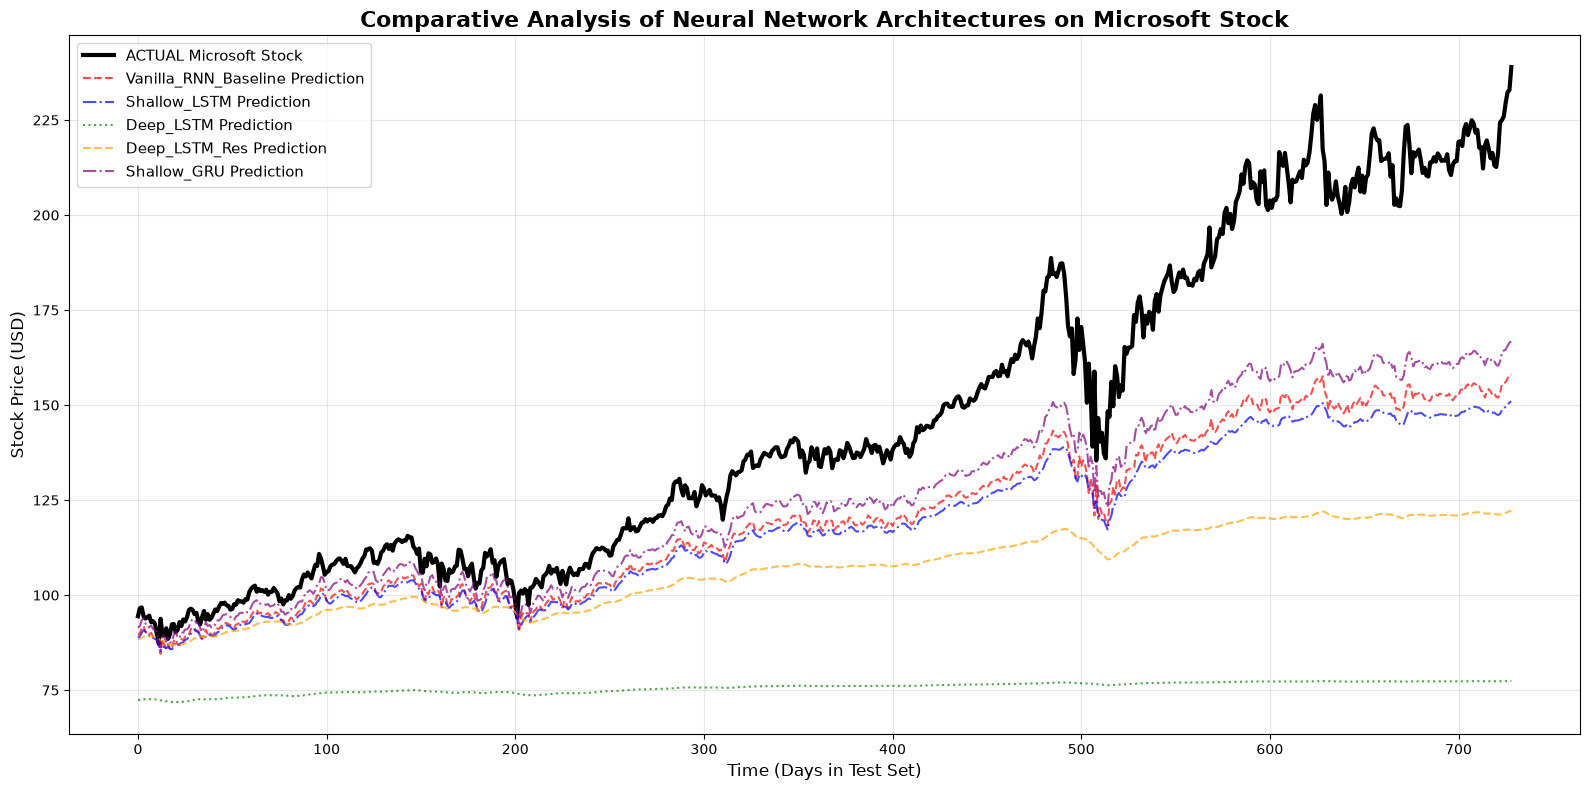

In [ ]:
# ==========================================
# VISUALIZZATION
# ==========================================
plt.figure(figsize=(16, 8))

# Actual Stock Price
plt.plot(test_actuals_unscaled, label='ACTUAL Microsoft Stock', color='black', linewidth=3)

# Plot all model predictions
colors = ['red', 'blue', 'green', 'orange', 'purple', 'cyan', 'magenta', 'brown', 'teal', 'pink']
line_styles = ['--', '-.', ':']

for idx, (exp_name, preds) in enumerate(all_predictions.items()):
    dynamic_color = colors[idx % len(colors)]
    dynamic_style = line_styles[idx % len(line_styles)]
    
    plt.plot(
        preds, 
        label=f'{exp_name} Prediction', 
        color=dynamic_color, 
        linestyle=dynamic_style, 
        alpha=0.7,
        linewidth=1.5
    )

plt.title('Comparative Analysis of Neural Network Architectures on Microsoft Stock', fontsize=16, fontweight='bold')
plt.xlabel('Time (Days in Test Set)', fontsize=12)
plt.ylabel('Stock Price (USD)', fontsize=12)
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plot_filename = f'../results/stock_predictions_{timestamp}.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')

plt.show()